# Week 10 – CNN Laboratory Activity

## Task 1: Problem Framing and Data Plan

**Dataset:** CIFAR-10

**Problem:** Multiclass image classification

**Input size:** 32 × 32 × 3 RGB images

**Number of classes:** 10

**Training images:** 40,000

**Validation images:** 10,000

**Testing images:** 10,000

**Preprocessing:** Normalize pixel values from 0–255 to 0–1.

**Random seed:** 42

**Augmentation:** None for the initial experiment.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

# Load CIFAR-10
(x_full, y_full), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

y_full = y_full.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Dataset: CIFAR-10")
print("Input size:", x_full.shape[1:])
print("Number of classes:", len(class_names))
print("Original training images:", len(x_full))
print("Official test images:", len(x_test))

Dataset: CIFAR-10
Input size: (32, 32, 3)
Number of classes: 10
Original training images: 50000
Official test images: 10000


In [38]:
SEED = 42

indices = np.arange(len(x_full))

train_idx, val_idx = train_test_split(
    indices,
    test_size=10000,
    random_state=SEED,
    stratify=y_full
)

x_train, y_train = x_full[train_idx], y_full[train_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]

print("Training images:", len(x_train))
print("Validation images:", len(x_val))
print("Testing images:", len(x_test))
print("Random seed:", SEED)

Training images: 40000
Validation images: 10000
Testing images: 10000
Random seed: 42


In [39]:
class_distribution = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10)
})

display(class_distribution)

,Class,Train,Validation,Test
0,airplane,4000,1000,1000
1,automobile,4000,1000,1000
2,bird,4000,1000,1000
3,cat,4000,1000,1000
4,deer,4000,1000,1000
5,dog,4000,1000,1000
6,frog,4000,1000,1000
7,horse,4000,1000,1000
8,ship,4000,1000,1000
9,truck,4000,1000,1000


Training shape: (40000, 32, 32, 3)
Validation shape: (10000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)
Pixel range: 0.0 to 1.0


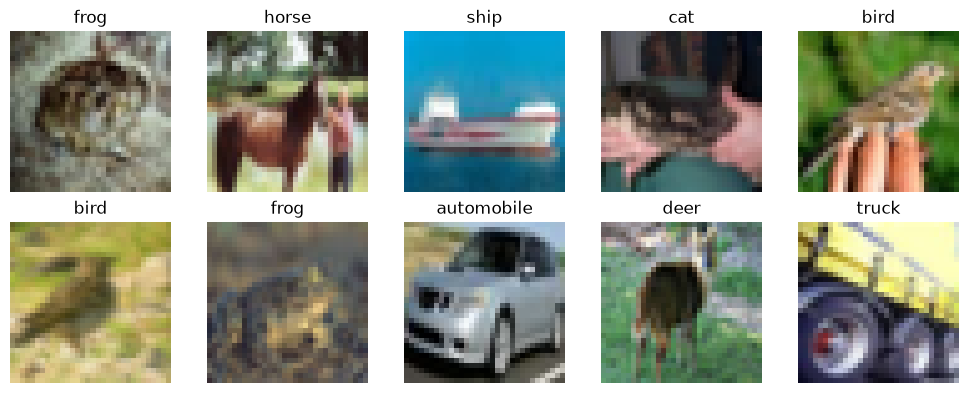

In [40]:
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Testing shape:", x_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Task 2: User-Defined Baseline CNN

### Architecture

Input (32 × 32 × 3)
→ Conv2D (32 filters, 3 × 3) + ReLU
→ MaxPooling2D (2 × 2)
→ Conv2D (64 filters, 3 × 3) + ReLU
→ MaxPooling2D (2 × 2)
→ Flatten
→ Dense (128, ReLU)
→ Dense (10, Softmax)

### Training Plan

- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 64
- Maximum epochs: 20
- Loss: Sparse categorical cross-entropy
- Metric: Accuracy
- Early stopping: Validation loss, patience of 3 epochs

In [44]:
from tensorflow.keras import layers, models

# Define the baseline CNN
baseline_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Display the baseline model summary
baseline_model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_22 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

baseline_history = baseline_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.4764 - loss: 1.4573 - val_accuracy: 0.5729 - val_loss: 1.2005
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.6164 - loss: 1.0889 - val_accuracy: 0.6189 - val_loss: 1.0840
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.6688 - loss: 0.9478 - val_accuracy: 0.6529 - val_loss: 0.9942
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.7061 - loss: 0.8469 - val_accuracy: 0.6724 - val_loss: 0.9562
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.7370 - loss: 0.7631 - val_accuracy: 0.6739 - val_loss: 0.9586
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.7628 - loss: 0.6893 - val_accuracy: 0.6646 - val_loss: 0.9922
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.7866 - loss: 0.6209 - val_accuracy: 0.6581 - val_loss: 1.0525
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.8109 - loss: 0.5558 - 

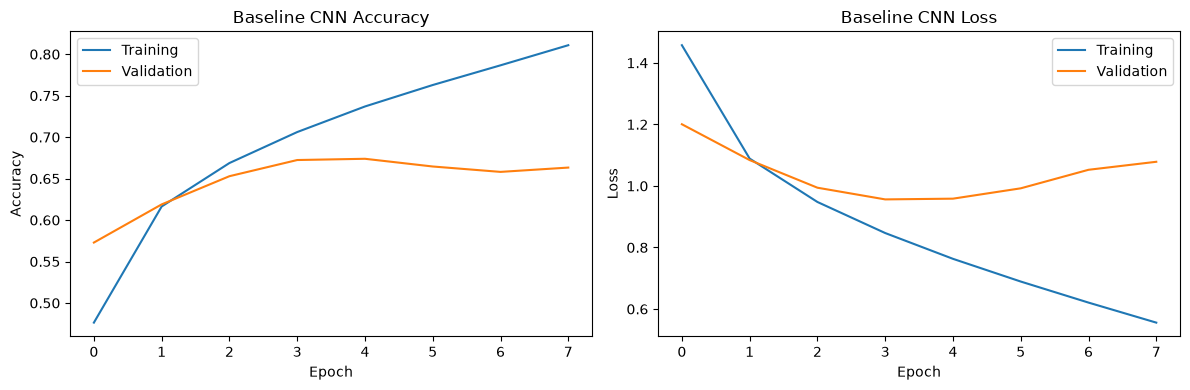

In [46]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history["accuracy"], label="Training")
plt.plot(baseline_history.history["val_accuracy"], label="Validation")
plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(baseline_history.history["loss"], label="Training")
plt.plot(baseline_history.history["val_loss"], label="Validation")
plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## Task 3: Stronger CNN

### Architecture

Input (32 × 32 × 3)

Block 1:
- Conv2D (32 filters) → BatchNormalization → ReLU
- Conv2D (32 filters) → BatchNormalization → ReLU
- MaxPooling2D → Dropout (0.20)

Block 2:
- Conv2D (64 filters) → BatchNormalization → ReLU
- Conv2D (64 filters) → BatchNormalization → ReLU
- MaxPooling2D → Dropout (0.30)

Block 3:
- Conv2D (128 filters) → BatchNormalization → ReLU

Classification head:
- GlobalAveragePooling2D
- Dense (128, ReLU)
- Dropout (0.40)
- Dense (10, Softmax)

### Training Plan

- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 64
- Maximum epochs: 20
- Early stopping: Validation loss, patience of 3 epochs

In [47]:
stronger_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(10, activation="softmax")
])

stronger_model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             

 Total params: 158,186 (617.91 KB)

 Trainable params: 157,546 (615.41 KB)

 Non-trainable params: 640 (2.50 KB)

In [48]:
stronger_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

stronger_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

stronger_history = stronger_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[stronger_early_stop],
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 86s 132ms/step - accuracy: 0.4401 - loss: 1.5222 - val_accuracy: 0.5186 - val_loss: 1.2730
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 79s 126ms/step - accuracy: 0.5804 - loss: 1.1652 - val_accuracy: 0.5591 - val_loss: 1.2011
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 120ms/step - accuracy: 0.6311 - loss: 1.0341 - val_accuracy: 0.6206 - val_loss: 1.0451
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 77s 123ms/step - accuracy: 0.6595 - loss: 0.9524 - val_accuracy: 0.6090 - val_loss: 1.1302
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 140ms/step - accuracy: 0.6844 - loss: 0.8871 - val_accuracy: 0.5905 - val_loss: 1.1509
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 133ms/step - accuracy: 0.7059 - loss: 0.8350 - val_accuracy: 0.5840 - val_loss: 1.2215


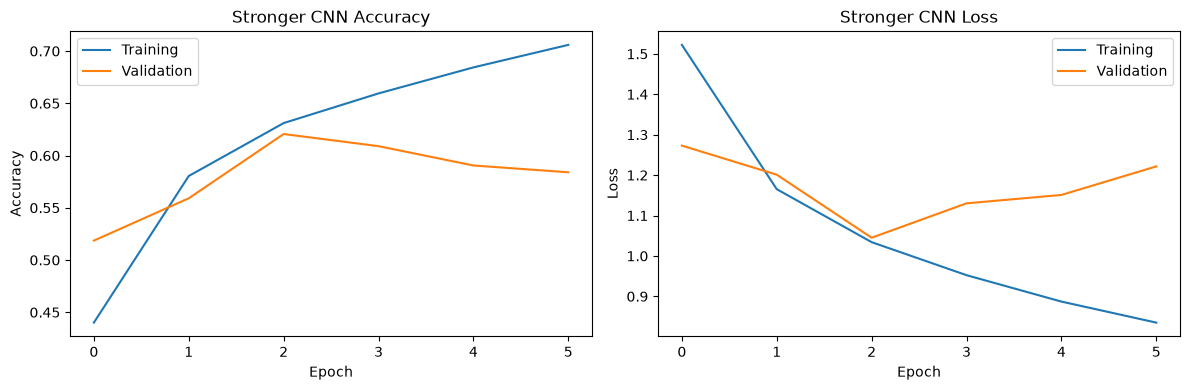

In [49]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(stronger_history.history["accuracy"], label="Training")
plt.plot(stronger_history.history["val_accuracy"], label="Validation")
plt.title("Stronger CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(stronger_history.history["loss"], label="Training")
plt.plot(stronger_history.history["val_loss"], label="Validation")
plt.title("Stronger CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [50]:
def get_best_validation(history):
    val_acc = history.history["val_accuracy"]
    best_index = int(np.argmax(val_acc))

    return val_acc[best_index] * 100, best_index + 1


baseline_val, baseline_epoch = get_best_validation(baseline_history)
stronger_val, stronger_epoch = get_best_validation(stronger_history)

baseline_test_loss, baseline_test_acc = baseline_model.evaluate(
    x_test, y_test, verbose=0
)

stronger_test_loss, stronger_test_acc = stronger_model.evaluate(
    x_test, y_test, verbose=0
)

print("BASELINE CNN")
print(f"Best validation accuracy: {baseline_val:.2f}%")
print(f"Best epoch: {baseline_epoch}")
print(f"Test accuracy: {baseline_test_acc * 100:.2f}%")

print("\nSTRONGER CNN")
print(f"Best validation accuracy: {stronger_val:.2f}%")
print(f"Best epoch: {stronger_epoch}")
print(f"Test accuracy: {stronger_test_acc * 100:.2f}%")

BASELINE CNN
Best validation accuracy: 67.39%
Best epoch: 5
Test accuracy: 67.75%

STRONGER CNN
Best validation accuracy: 62.06%
Best epoch: 3
Test accuracy: 62.11%


In [51]:
results = pd.DataFrame([
    {
        "Model": "User-Defined Baseline",
        "Best Val Acc (%)": round(baseline_val, 2),
        "Epoch": baseline_epoch,
        "Test Acc (%)": round(baseline_test_acc * 100, 2),
        "Notes": "2 convolution blocks; no BatchNorm or Dropout"
    },
    {
        "Model": "Stronger CNN",
        "Best Val Acc (%)": round(stronger_val, 2),
        "Epoch": stronger_epoch,
        "Test Acc (%)": round(stronger_test_acc * 100, 2),
        "Notes": "Deeper CNN; BatchNorm and Dropout"
    }
])

display(results)

,Model,Best Val Acc (%),Epoch,Test Acc (%),Notes
0,User-Defined Baseline,67.39,5,67.75,2 convolution blocks; no BatchNorm or Dropout
1,Stronger CNN,62.06,3,62.11,Deeper CNN; BatchNorm and Dropout


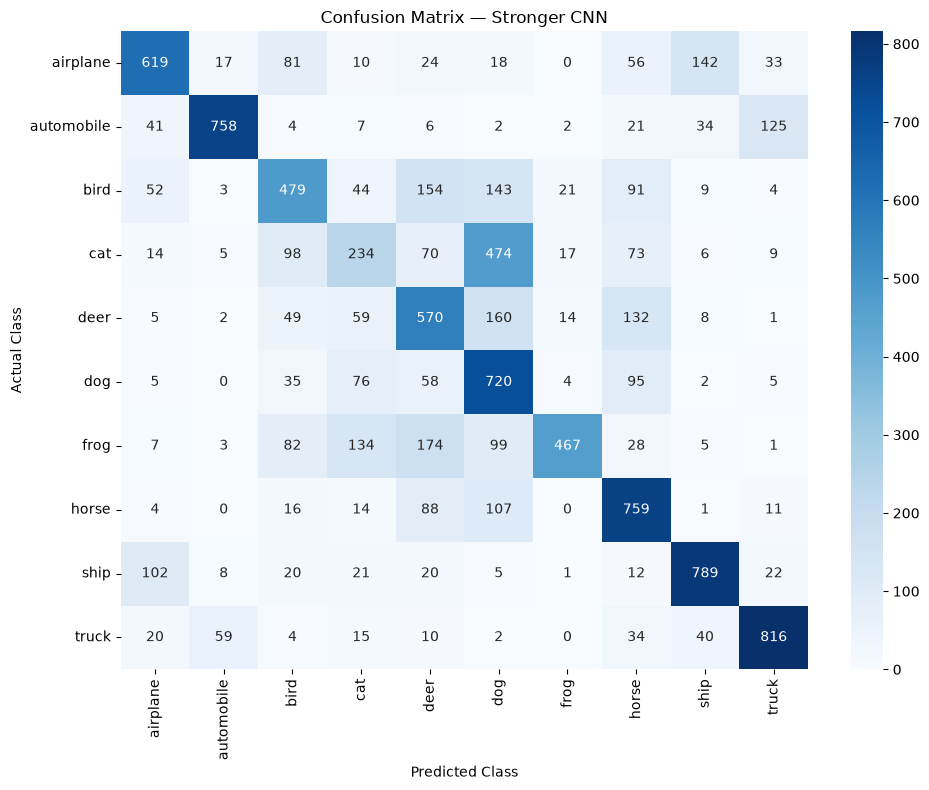

In [52]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_prob = stronger_model.predict(x_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(
    y_test, y_pred, labels=np.arange(10)
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Stronger CNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()